# 03 · Five models, one average

## What this notebook shows

The final forecast of this project, called `ens_mean`, is **the plain average of five
models' forecasts**. This notebook shows that, step by step:

1. The five models (the "candidates") in plain words.
2. One day and one division: what each model predicted, and the average.
3. A proof that the average computed here by hand is exactly the official ensemble.
4. How accurate everything was on 2022–2024, and how sure we are that the ensemble really
   beats the simple rules.
5. Why averaging helps at all.

By default the notebook **reads saved results** and runs in seconds. Setting
`RERUN = True` (first code cell) re-trains all the models from scratch, which takes about
5 minutes, and checks that the result comes out the same.

## Glossary

- **Model**: a recipe that turns past counts (and the calendar) into a forecast. Here we
  use five of them.
- **Ensemble**: a forecast made by combining several models. Ours just averages five.
- **Baseline**: a simple rule of thumb the models must beat (see notebook 02):
  `same_wd_13w` (average of the last 13 same weekdays) and `plain_28d` (average of the
  last 28 days).
- **MAE (mean absolute error)**: the average size of the miss, ignoring whether it was too
  high or too low. An MAE of 8.3 means "off by about 8 interventions per division per day
  on average". **Lower is better.**
- **Validation period**: past days (here 2021–2024) where we pretend to forecast each day
  using only the data known at the time, then compare with what really happened. The
  ensemble is scored on 2022–2024 because 2021 is kept as history for the weighted
  variant.

## Setup

`RERUN` is the only switch in this notebook. Leave it `False` to read the saved results.
Set it to `True` to re-train every model and redo every forecast in memory (about
5 minutes); nothing is written to disk either way.

In [ ]:
# False: read the saved forecasts (seconds).
# True: re-train the five models and both baselines over 2021-2024, rebuild the
# ensemble in memory and check that its MAE matches the saved report (about 5 min).
# Nothing is ever written to data/ or reports/.
RERUN = False

Load the libraries and the project's package. The `chdir` line makes the notebook work
whether it starts from the repo root or from `notebooks/`. `check` stops the notebook with
an error if a number doesn't match, so a wrong result can't slip through.

In [ ]:
import datetime as dt
import json
import os
from pathlib import Path
from typing import cast

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from ycit440_sim_forecast import baseline, ensemble, evaluate, models, spec

# VS Code starts notebooks in notebooks/; every path below is relative to the repo root.
if not Path("pyproject.toml").exists():
    os.chdir(Path.cwd().parent)

Display settings, the list of the five candidates, and the two baselines.

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (10, 4)})
pl.Config.set_tbl_rows(30)
CANDIDATES = list(models.ENSEMBLE_CANDIDATES)
BASELINES = ["same_wd_13w", "plain_28d"]
FINAL = ensemble.FINAL_MODEL  # "ens_mean"


def check(cond: bool, msg: str) -> None:
    """Stop the notebook when something doesn't match."""
    if not cond:
        raise AssertionError(msg)

Load the saved results: every model's forecast for every day of 2021–2024
(`model_predictions_v2`), the three ensembles' forecasts for 2022–2024
(`ensemble_predictions_v2`), and the summary report with all the scores.

In [ ]:
preds = pl.read_parquet("data/processed/model_predictions_v2.parquet")
ens = pl.read_parquet("data/processed/ensemble_predictions_v2.parquet")
report = json.loads(Path("reports/ensemble_validation.json").read_text())
print(f"model forecasts: {preds.height:,} rows, {preds['model'].n_unique()} models")
ens_names = ens["model"].unique().sort().to_list()
print(f"ensemble forecasts: {ens.height:,} rows, models {ens_names}")
print(f"final model: {report['final_model']}")

model forecasts: 131,490 rows, 15 models
ensemble forecasts: 19,728 rows, models ['ens_mean', 'ens_median', 'ens_weighted']
final model: ens_mean


## 1. The five candidates

Fifteen model setups were tested; these five were picked because they are good **and**
make different kinds of mistakes.

| Name | What it is, in plain words | What it brings |
| ---- | -------------------------- | -------------- |
| `lgbm_poisson_raw` | LightGBM (a gradient-boosted decision-tree model) predicting the count from recent counts and the calendar, with no level offset. | It must learn the level itself, so it can't forecast outside the range it was trained on. |
| `lgbm_poisson` | The same model, but starting from the recent 28-day level (the "offset"), so the trees only learn the adjustment (for example, how much a given weekday, month or holiday usually differs from the recent level). | It follows level shifts automatically. |
| `cat_tweedie` | CatBoost, a different tree library with a different tree shape and loss, also starting from the 28-day level. | Different errors from the LightGBM models. |
| `ets_weekly` | Exponential smoothing per division, a classical time-series method that keeps a smoothed level plus a weekly pattern. No trees, no features. | A simple method with a different kind of error. |
| `topdown_ets` | The same smoothing on the city-wide total, then split among divisions by each one's share of the last 28 days. | The city total is less noisy than a single division. |

A **decision tree** is a flowchart of yes/no questions ("is it a Saturday?", "was last
week above average?") that ends in a number; LightGBM and CatBoost add up hundreds of small
trees. **Exponential smoothing** is a running average that gives more weight to recent
days. Every model is re-trained at the start of each month using only the data available
at that time.

## 2. The key slide: one day, one division

The same forecast as in notebook 02: issued on **2024-06-14** for **Saturday 2024-06-15**,
**Division 3**. Here is what each model said, and the plain average of the five
candidates. The baselines are shown for comparison but are **not** part of the average.

In [ ]:
ISSUE, DIV = dt.date(2024, 6, 14), 3
day = preds.filter(
    pl.col("issue_date") == ISSUE,
    pl.col("DIVISION") == DIV,
    pl.col("model").is_in(CANDIDATES + BASELINES),
).select("model", "y_true", "y_pred")
actual = day["y_true"][0]
average = day.filter(pl.col("model").is_in(CANDIDATES))["y_pred"].mean()
print(f"actual count: {actual:.0f}   average of the 5 candidates: {average:.1f}")

actual count: 64   average of the 5 candidates: 63.1


As a table, sorted the way we'll show it: the five candidates, the ensemble (their
average), then the two baselines. "Miss" is forecast minus actual (negative = too low).

In [ ]:
order = [*CANDIDATES, "average of the 5 (ens_mean)", *BASELINES]
avg_row = pl.DataFrame({"model": [order[5]], "y_true": [actual], "y_pred": [average]})
slide = (
    pl.concat([day, avg_row])
    .with_columns(miss=pl.col("y_pred") - pl.col("y_true"))
    .sort(pl.col("model").replace_strict(order, list(range(len(order)))))
    .with_columns(pl.col("y_pred", "miss").round(1))
)
slide

model,y_true,y_pred,miss
str,f64,f64,f64
"""lgbm_poisson_raw""",64.0,62.3,-1.7
"""lgbm_poisson""",64.0,65.0,1.0
"""cat_tweedie""",64.0,67.5,3.5
"""ets_weekly""",64.0,58.5,-5.5
"""topdown_ets""",64.0,62.2,-1.8
"""average of the 5 (ens_mean)""",64.0,63.1,-0.9
"""same_wd_13w""",64.0,60.8,-3.2
"""plain_28d""",64.0,71.0,7.0


The same numbers as a picture. Each dot is one forecast; the black line is what really
happened (64 interventions). The individual models are scattered on both sides of the
truth, from 58 to 67; their average (red) lands within one intervention of it.

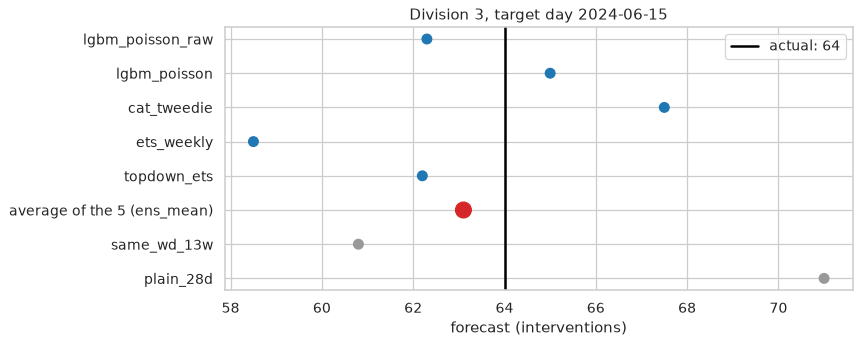

In [ ]:
colors = ["#1f77b4"] * 5 + ["#d62728"] + ["0.6"] * 2
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(slide["y_pred"], slide["model"], c=colors, s=[60] * 5 + [160] + [60] * 2)
ax.axvline(actual, color="black", lw=2, label=f"actual: {actual:.0f}")
ax.invert_yaxis()
ax.set(
    xlabel="forecast (interventions)", title=f"Division {DIV}, target day 2024-06-15"
)
ax.legend(loc="upper right");

## 3. Proof: the ensemble really is just the average

We now recompute `ens_mean` ourselves for **every** day and division of 2022–2024: keep the
five candidates, group the rows by forecast day and division, and take the mean. The
package leaves the average empty if any member is missing, so we do the same.

In [ ]:
scored = preds.filter(
    pl.col("model").is_in(CANDIDATES),
    pl.col("target_start") >= dt.date(2022, 1, 1),
    pl.col("target_end") <= dt.date(2024, 12, 31),
)
by_hand = (
    scored.group_by("issue_date", "DIVISION")
    .agg(
        members=pl.len(),
        y_true=pl.col("y_true").first(),
        y_pred=pl.when(pl.col("y_pred").null_count() == 0).then(
            pl.col("y_pred").mean()
        ),
    )
    .sort("issue_date", "DIVISION")
)
check((by_hand["members"] == 5).all(), "every forecast should have 5 members")

Compare our hand-made average with the official `ens_mean` forecasts saved by the
package: same number of rows, same days, and the same numbers (up to rounding in the last
decimal places).

In [ ]:
official = ens.filter(pl.col("model") == FINAL).sort("issue_date", "DIVISION")
check(by_hand.height == official.height, "different number of rows")
same_keys = by_hand.select("issue_date", "DIVISION").equals(
    official.select("issue_date", "DIVISION")
)
check(same_keys, "different days or divisions")
check(
    np.allclose(by_hand["y_pred"].to_numpy(), official["y_pred"].to_numpy()), "values"
)
print(f"{by_hand.height:,} forecasts match the official ens_mean")

6,576 forecasts match the official ens_mean


And the score: MAE is the average of |actual − forecast|, over the days whose actual
count is known (6 rows have no actual, because 2024-12-31 is missing from the data). It
matches the official report's 8.257.

In [ ]:
known = by_hand.filter(pl.col("y_true").is_not_null())
mae = cast(float, (known["y_true"] - known["y_pred"]).abs().mean())
print(f"ens_mean by hand: MAE {mae:.3f} over {known.height:,} forecasts")
official_mae = next(r["mae"] for r in report["overall"] if r["model"] == FINAL)
check(round(mae, 3) == official_mae == 8.257, f"MAE {mae:.3f} != {official_mae}")

ens_mean by hand: MAE 8.257 over 6,570 forecasts


## 4. Results on 2022–2024

MAE for every model, from the saved report (all scored on the same 6,570 forecasts).
`bias` is the average of forecast − actual: negative means the model tends to guess a bit
low. A slightly negative bias is normal here, because the counts have occasional very high
days that no model sees coming.

In [ ]:
overall = (
    pl.DataFrame(report["overall"]).select("model", "mae", "bias", "n").sort("mae")
)
overall

model,mae,bias,n
str,f64,f64,i64
"""ens_mean""",8.257,-1.293,6570
"""ens_weighted""",8.282,-1.189,6570
"""ens_median""",8.33,-1.638,6570
"""lgbm_poisson_raw""",8.534,-2.073,6570
"""cat_tweedie""",8.544,-1.634,6570
"""lgbm_poisson""",8.618,-1.318,6570
"""ets_weekly""",8.773,-1.03,6570
"""same_wd_13w""",8.889,-0.562,6570
"""topdown_ets""",8.912,-0.408,6570


The same MAEs as a chart. Red is the final ensemble, light red the two other ensembles,
blue the five candidates, grey the baselines. The axis starts at 7.5, not 0, so the
differences are visible; they are real but modest (about 7% between `ens_mean` and
`same_wd_13w`).

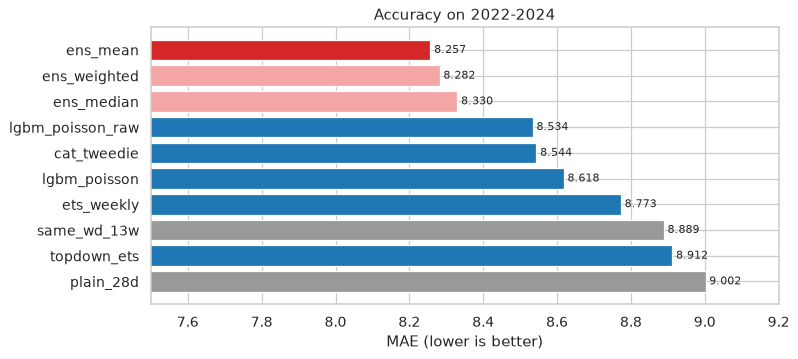

In [ ]:
def color(name: str) -> str:
    """Bar colour by role."""
    if name == FINAL:
        return "#d62728"
    if name.startswith("ens_"):
        return "#f4a6a6"
    return "#1f77b4" if name in CANDIDATES else "0.6"


fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(
    overall["model"], overall["mae"], color=[color(m) for m in overall["model"]]
)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(7.5, 9.2), xlabel="MAE (lower is better)", title="Accuracy on 2022-2024");

**Why the mean, and not the median or the weighted average?** Three ways of combining the
five were tested. The plain mean scored best (8.257 vs 8.282 weighted and 8.330 median),
and it **learns nothing**: there are no weights to fit, so nothing can be over-tuned to
the past. It was chosen before the final test on 2025 (notebook 04).

### How sure are we?

A difference of a few tenths could be luck. To check, the comparison was redone 2,000
times on random re-draws of whole weeks (a "bootstrap"), giving a **95% range** for each
difference. `diff` is ensemble MAE minus reference MAE: negative means the ensemble is
better. When the whole range (`ci_low` to `ci_high`) is below zero, the improvement is
very unlikely to be luck.

In [ ]:
boot = report["bootstrap"]
rows = [r for refs in boot["references"].values() for r in refs]
rows += boot["best_single"]["results"]
cols = ["model", "reference", "mae_model", "mae_reference", "diff", "ci_low", "ci_high"]
pl.DataFrame(rows).select(cols).sort("reference", "model")

model,reference,mae_model,mae_reference,diff,ci_low,ci_high
str,str,f64,f64,f64,f64,f64
"""ens_mean""","""lgbm_poisson_raw""",8.257,8.534,-0.277,-0.411,-0.152
"""ens_median""","""lgbm_poisson_raw""",8.33,8.534,-0.204,-0.316,-0.101
"""ens_weighted""","""lgbm_poisson_raw""",8.282,8.534,-0.253,-0.389,-0.126
"""ens_mean""","""plain_28d""",8.257,9.002,-0.745,-1.081,-0.453
"""ens_median""","""plain_28d""",8.33,9.002,-0.672,-1.017,-0.391
"""ens_weighted""","""plain_28d""",8.282,9.002,-0.72,-1.083,-0.399
"""ens_mean""","""same_wd_13w""",8.257,8.889,-0.632,-0.826,-0.447
"""ens_median""","""same_wd_13w""",8.33,8.889,-0.559,-0.732,-0.394
"""ens_weighted""","""same_wd_13w""",8.282,8.889,-0.607,-0.821,-0.406


Every range is entirely below zero: `ens_mean` beats `same_wd_13w` by about 0.63
interventions per division per day (95% range 0.45 to 0.83), and it even beats the best
single model, `lgbm_poisson_raw`, by 0.28 (0.15 to 0.41). Note that `lgbm_poisson_raw`
was picked as "best" after looking at the results, which flatters it; the ensemble wins
anyway.

## 5. Why averaging helps

Each model makes mistakes (forecast − actual). If two models always missed by the same
amount in the same direction, averaging them would change nothing. The heatmap shows how
closely each pair's mistakes move together, from 0 (unrelated) to 1 (identical).

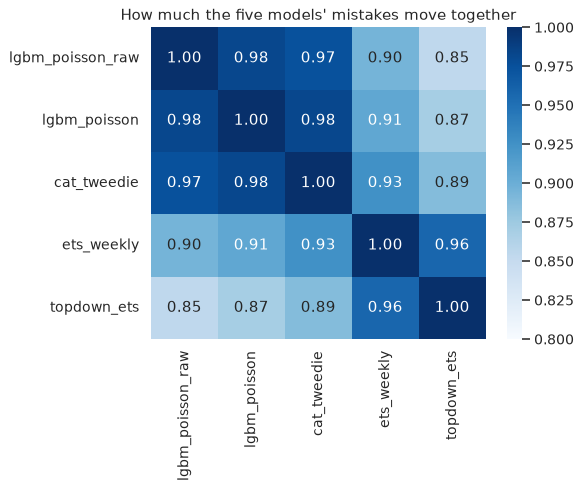

In [ ]:
errors = (
    scored.with_columns(error=pl.col("y_pred") - pl.col("y_true"))
    .pivot("model", index=["issue_date", "DIVISION"], values="error")
    .drop_nulls()
    .select(CANDIDATES)
)
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    errors.corr().to_numpy(),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0.8,
    vmax=1,
    xticklabels=CANDIDATES,
    yticklabels=CANDIDATES,
    ax=ax,
)
ax.set_title("How much the five models' mistakes move together");

All the models struggle on the same surprising days (storms, heat waves), so their
mistakes are strongly linked (0.85 to 0.98). But they are not identical: the tree models
and the smoothing models disagree the most (0.85 to 0.93). **Mistakes that don't move
together partly cancel out** in the average: when the trees guess too high and the
smoothing models too low, the average lands in between. That is where the ensemble's gain
comes from.

## 6. Accuracy by division

The ensemble against the official baseline, division by division. Division 1 is the
smallest (fewest calls), so its errors are smallest too. The ensemble is better in every
division.

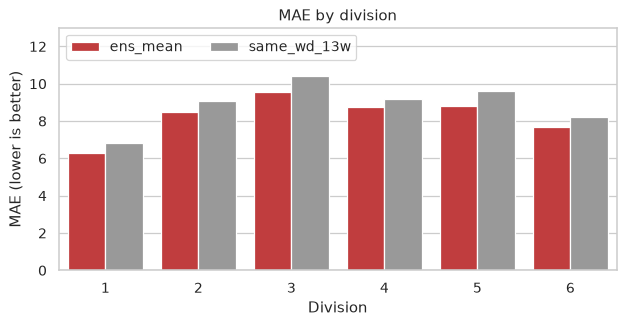

In [ ]:
by_div = pl.DataFrame(report["by_division"]).filter(
    pl.col("model").is_in([FINAL, "same_wd_13w"])
)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(
    by_div.to_pandas(),
    x="DIVISION",
    y="mae",
    hue="model",
    ax=ax,
    hue_order=[FINAL, "same_wd_13w"],
    palette=["#d62728", "0.6"],
)
ax.set(xlabel="Division", ylabel="MAE (lower is better)", title="MAE by division")
ax.set_ylim(0, 13)
ax.legend(title=None, ncols=2, loc="upper left");

## 6b. How spread out are the misses?

MAE tells you how big a miss is on average. It does not tell you whether the misses are
all about the same size, or whether most are small and a few are huge. Two numbers answer
that:

- **Variance (of the errors).** Take each miss (forecast − actual), subtract the average
  miss (the bias), square the result, and average those squares over all the forecasts.
  We divide by **n, the number of division-days**, not by n − 1.
- **Standard deviation (SD).** The square root of the variance, so it is back in calls.
  It is **the typical distance of a miss from the average miss**.

The SD comes out bigger than the MAE because squaring makes a big miss count much more
than a small one. A few days like the **April 2023 ice storm** (Division 1 got 384 calls
on 2023-04-06 against a forecast of about 26) add a lot to the SD but only a little to
the MAE.

The table below is computed straight from the saved forecasts with
`evaluate.error_spread`, for the final ensemble and the two baselines, on 2022–2024
(anomaly days included, as in the MAE tables).

In [ ]:
SPREAD_MODELS = [FINAL, *BASELINES]
validation = pl.concat([preds, ens], how="diagonal_relaxed").filter(
    pl.col("model").is_in(SPREAD_MODELS),
    pl.col("target_start").is_between(dt.date(2022, 1, 1), dt.date(2024, 12, 31)),
)
spread = pl.concat(
    [
        evaluate.error_spread(validation, ["DIVISION"]).with_columns(
            pl.col("DIVISION").cast(pl.String)
        ),
        evaluate.error_spread(validation).with_columns(DIVISION=pl.lit("All")),
    ],
    how="diagonal",
)


def spread_table(value: str) -> pl.DataFrame:
    """One row per division (plus "All"), one column per model."""
    return (
        spread.pivot("model", index="DIVISION", values=value)
        .select("DIVISION", *SPREAD_MODELS)
        .with_columns(pl.col(SPREAD_MODELS).round(2))
    )


saved = json.loads(Path("reports/error_spread.json").read_text())
saved_sd = next(
    r["error_sd"] for r in saved["validation"]["overall"] if r["model"] == FINAL
)
ens_sd = spread.filter(pl.col("DIVISION") == "All", pl.col("model") == FINAL)[
    "error_sd"
]
check(round(ens_sd.item(), 3) == saved_sd, f"SD {ens_sd.item()} != report {saved_sd}")
print("Standard deviation of the errors (calls), 2022-2024:")
spread_table("error_sd")

Standard deviation of the errors (calls), 2022-2024:


DIVISION,ens_mean,same_wd_13w,plain_28d
str,f64,f64,f64
"""1""",15.72,16.28,16.47
"""2""",14.02,14.57,14.78
"""3""",18.4,19.16,19.66
"""4""",13.51,13.95,14.15
"""5""",15.54,16.43,16.81
"""6""",10.5,11.06,11.41
"""All""",14.82,15.45,15.75


In [ ]:
print("Variance of the errors (calls squared), 2022-2024:")
spread_table("error_var")

Variance of the errors (calls squared), 2022-2024:


DIVISION,ens_mean,same_wd_13w,plain_28d
str,f64,f64,f64
"""1""",246.98,264.9,271.27
"""2""",196.6,212.25,218.33
"""3""",338.72,367.18,386.57
"""4""",182.45,194.72,200.18
"""5""",241.64,270.02,282.72
"""6""",110.17,122.27,130.09
"""All""",219.64,238.59,248.2


The SDs as a chart, division by division (red = the ensemble, grey = the baselines).

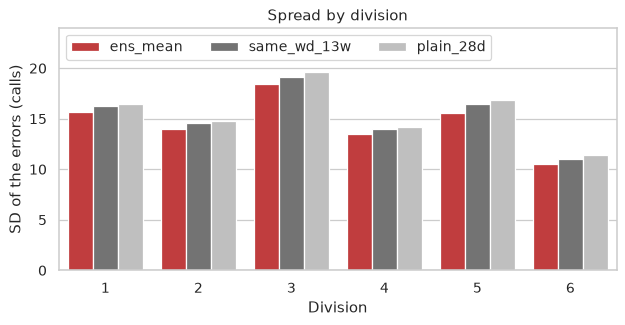

In [ ]:
by_div_sd = spread.filter(pl.col("DIVISION") != "All")
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(
    by_div_sd.to_pandas(),
    x="DIVISION",
    y="error_sd",
    hue="model",
    ax=ax,
    hue_order=SPREAD_MODELS,
    palette=["#d62728", "0.45", "0.75"],
)
ax.set(xlabel="Division", ylabel="SD of the errors (calls)", title="Spread by division")
ax.legend(title=None, ncols=3, loc="upper left")
ax.set_ylim(0, 24);

**How to read this.** The ensemble has the smallest SD in every division, so its misses
are not only smaller on average but also less spread out. Division 3 has the widest spread
(SD about 18.4 for `ens_mean`). Division 1 is the surprise: it has the **smallest MAE**
(above) but the **second-widest spread** (about 15.7), because it is a small division and
the April 2023 ice storm pushed its count to many times its usual level. Division 6 has
the tightest spread (about 10.5).

## 7. Optional: re-train everything (`RERUN = True`)

This re-creates the saved forecasts from scratch, exactly as the pipeline does: for every
day of 2021–2024 it forecasts with only the data known at the time (`rolling_origin`),
re-training the five candidates at the start of each month. The two baselines run
alongside. Everything stays in memory.

In [ ]:
if RERUN:
    history = pl.read_parquet("data/processed/division_day.parquet")
    anomalies = pl.read_parquet("data/processed/anomaly_days.parquet")
    members = [m for m in models.default_models() if m.name in CANDIDATES]
    rules = [baseline.SameWeekdayMean(13), baseline.PlainMean()]
    start, end = dt.date(2021, 1, 1), dt.date(2024, 12, 31)
    fresh = evaluate.rolling_origin(history, members + rules, spec.V2_DAILY, start, end)
    fresh = evaluate.flag_anomalies(fresh, anomalies)
    print(f"{fresh.height:,} fresh forecasts from {fresh['model'].n_unique()} models")

Then combine the fresh forecasts into the three ensembles with the package's own
function, and check that `ens_mean` scores exactly the saved 8.257.

In [ ]:
if RERUN:
    rebuilt, _ = ensemble.combine_oof(fresh, ensemble.EnsembleConfig())
    rescored = evaluate.score(rebuilt).select("model", "mae", "n")
    print(rescored)
    fresh_mae = rescored.filter(pl.col("model") == FINAL)["mae"][0]
    check(round(fresh_mae, 3) == 8.257, f"re-trained ens_mean MAE {fresh_mae:.3f}")
    print(f"re-trained ens_mean MAE {fresh_mae:.3f} matches the saved report")